# Mean-signal kurtosis: real human diffusion MRI


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`signals`，shape `(1, 3, 96, 96, 496)`，dtype `<i2`：MRI magnitude observations, ADU; axes batch, native slice, native x, native y, encoding；`bvalues`，shape `(1, 496)`，dtype `<f8`：Diffusion weighting in s per mm squared, matched to encoding axis；`gradient_directions`，shape `(1, 496, 3)`，dtype `<f8`：Unitless Cartesian encoding direction components from deposited table; zero for b=0。未知量为三层脑体素D/K/S0参数图。

获取模型：方向均值信号S(b)=S0 exp(-bD+b²D²K/6)。

如何恢复：src.solvers.fit_shells/reconstruct：观测幅度平方加权的闭式log信号最小二乘。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell7原生三层图；9权重/模型范围；11固定ROI方向均值实测与模型；13跨层支持/残差统计。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留4个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


This notebook reconstructs three full native 96 by 96 planes, slices 8–10, using all 496 deposited magnitude images. An observation-only support is fixed before fitting: the b=0 image must exceed 40 ADU. No output-derived screening or clipping is used. Negative fitted kurtosis remains a limitation to inspect.

Powder averaging gives one mean $\bar S(b)$ for each diffusion weighting $b$ (s/mm²). The model is $\log\bar S=\log S_0-bD+b^2D^2K/6$, where $D$ is mean-signal diffusivity (mm²/s), $K$ is dimensionless mean-signal kurtosis, and $S_0$ is fitted baseline ADU. This finite-b expansion measures curvature of rotationally averaged signal; it does not infer a directional tensor, an orientation distribution, or a uniquely identified axon fraction.

For each voxel, form $B=[-b,b^2/6,1]$ and weights $W=\mathrm{diag}(n_b\bar S_b^2)$, where $n_b$ is the number of directions in that shell. The original normal-equation solution is $p=(B^TWB)^+B^TW\log\bar S$. The superscript + is the Moore–Penrose inverse. Then $D=p_0$, $K=p_1/D^2$, and $S_0=\exp(p_2)$. The exact multiplication order $(1/6)b^2$ and the original signal floor 0.0001 ADU are retained. This is a closed-form inverse, without iterative optimization.

This review compares fresh reconstruction against the independent original MSDKI execution and performs actual unweighted, reduced-shell, and lower-order Gaussian fits. The supplied original tutorial also discusses compartment conversions and tensor kurtosis; those are distinct physical models and are not claimed as this benchmark's selected inverse. The plotted comparisons here test this selected mean-signal expansion directly.

## 2. Data

All 496 diffusion encodings are included. Spatial slices are original zero-based indices 8, 9, and 10; the full 96 by 96 detector field is retained. Data are the deposited magnitude observations without additional denoising, motion correction, resampling, or synthesized noise.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| signals | (1, 3, 96, 96, 496) | int16 | MRI magnitude observations, ADU; axes batch, native slice, native x, native y, encoding |
| bvalues | (1, 496) | float64 | Diffusion weighting in s per mm squared, matched to encoding axis |
| gradient_directions | (1, 496, 3) | float64 | Unitless Cartesian encoding direction components from deposited table; zero for b=0 |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Scanner | Siemens Trio | dimensionless | Human 3 T system |
| Field strength | 3 | tesla | Static magnetic field |
| Receiver | 32-channel head coil | channel | Acquisition receiver |
| Sequence | Double-spin-echo diffusion EPI with CSF suppression | dimensionless | Magnitude image acquisition |
| b shells | 0; 200 through 3000 in increments of 200 | s/mm squared | One b=0 image and 33 directions at every nonzero shell |
| Voxel spacing | 2.5, 2.5, 2.500000476837158 | mm | Stored native NIfTI x,y,z spacing, including original precision |
| Repetition time | 7200 | ms | TR |
| Echo time | 116 | ms | TE |
| Inversion time | 2100 | ms | CSF suppression TI |
| Original volume | 96 by 96 by 19 | voxel | Native geometry |
| Included slices | 8, 9, 10 | zero-based index | Three central native planes, no in-plane crop |
| Phase encoding | Anterior to posterior | dimensionless | EPI acquisition direction |
| Angular sampling | 24-point spherical design plus 9 fast-kurtosis directions | dimensionless | 33-direction shell sampling; use supplied vectors |
| Reported b=0 SNR | Approximately 39 | dimensionless | Depositor tissue-average estimate; no per-voxel noise standard deviation supplied |
| Spatial boundary | Independent voxel estimation | dimensionless | No spatial interpolation or wraparound |

Native voxel indices (i,j,k) map to world millimeters through the acquisition affine below; k takes values 8,9,10 for the output slices. Vector components follow the deposited encoding table and are used only for identifying directional sampling; the powder-average inverse is rotationally invariant.


$$
\begin{pmatrix}X\\Y\\Z\\1\end{pmatrix}=
\begin{pmatrix}
-2.497706413269043&0.08375494927167892&0.06668981164693832&113.64055633544922\\
0.069154292345047&2.4509189128875732&-0.4880725145339966&-104.14154052734375\\
0.0817319005727768&0.48577991127967834&2.4509875774383545&-31.504009246826172\\
0.0&0.0&0.0&1.0
\end{pmatrix}
\begin{pmatrix}i\\j\\k\\1\end{pmatrix}.
$$


X,Y,Z denote world coordinates; i,j,k denote native zero-based voxel indices. Absolute orientation is not an evaluation alignment degree of freedom.

## 3. Physics

At shell $b$ in s/mm^2, the direction-averaged magnitude follows

$$
\bar S(b)=S_0\exp(-bD+b^2D^2K/6).
$$

$D$ is diffusivity in mm^2/s, $K$ is dimensionless mean-signal kurtosis and $S_0$ is baseline ADU. The finite-b expansion can fail at high weighting and does not describe a directional tensor. Shell averaging changes precision: $n_b$ independent directions reduce variance of the mean.

## 4. Method

With observed shell means $y_b$, construct $B_b=[-b,b^2/6,1]$, $W=\operatorname{diag}(n_by_b^2)$ and $p=[D,D^2K,\log S_0]^T$. The source-convention inverse is

$$
p=(B^TWB)^+B^TW\log y.
$$

The plus denotes a Moore-Penrose pseudoinverse. Retain the 0.0001 ADU logarithm floor and multiplication order; unpack $K=p_1/D^2$. The support uses measured b=0 intensity above 40 ADU. There is no iterative optimizer or positivity correction; negative kurtosis is retained for diagnosis.

## 5. Results




In [1]:
from pathlib import Path
import os,sys,time,json,platform,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1'
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/main.py').exists())
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import run_experiments,figures,export_figures,relative_l2
try:
    import torch
    torch.set_num_threads(1)
except ImportError:
    pass
print('Python',platform.python_version(),'NumPy',np.__version__,'CPU',platform.platform())
data=load_data(root/'data/raw_data.npz')
start=time.perf_counter()
fresh=reconstruct(data)
reconstruction_runtime=time.perf_counter()-start
np.savez_compressed(root/'output/reconstruction.npz',**fresh)
np.savez_compressed(root/'notebooks/reference_outputs/cleaned.npz',**fresh)
print('Fresh complete benchmark reconstruction seconds:',reconstruction_runtime)
print({k:(v.shape,str(v.dtype)) for k,v in fresh.items()})


Python 3.11.11 NumPy 2.4.6 CPU Windows-10-10.0.26200-SP0
Fresh complete benchmark reconstruction seconds: 0.3065068998839706
{'diffusivity': ((1, 3, 96, 96), 'float64'), 'reconstruction': ((1, 3, 96, 96), 'float64'), 'baseline': ((1, 3, 96, 96), 'float64')}


### Independent numerical comparison and evaluation

The reference below was captured by running the original source on exactly these observations before local extraction. It is identified as an upstream method result; no independently measured specimen truth is available. Every required quantity is evaluated.


In [2]:
upstream=np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False)
spec=importlib.util.spec_from_file_location('review_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(root/'output/reconstruction.npz')
assert exit_code==0,report
(root/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(report,indent=2))

original_mapping={'diffusivity': 'output_diffusivity', 'reconstruction': 'output_kurtosis', 'baseline': 'output_baseline'}
print("Direct original-versus-fresh array comparisons:", {k:relative_l2(fresh[k],upstream[v][None]) for k,v in original_mapping.items()})


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "diffusivity_relative_l2": 0.0,
    "reconstruction_relative_l2": 0.0,
    "baseline_relative_l2": 0.0,
    "forward_shell_rmse": 5.002890195639437
  },
  "thresholds": {
    "diffusivity_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "reconstruction_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "baseline_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "forward_shell_rmse": {
      "comparison": "<=",
      "boundary": 5.503179215203381
    }
  },
  "errors": []
}
Direct original-versus-fresh array comparisons: {'diffusivity': 0.0, 'reconstruction': 0.0, 'baseline': 0.0}


### Fresh experiment suite

All alternatives below are actively recomputed with local modules. No archived output is presented as a new alternative. Numerical source values are retained for the displayed experiments.


In [3]:
experiment_start=time.perf_counter()
experiments=run_experiments(data,fresh)
experiment_runtime=time.perf_counter()-experiment_start
np.savez_compressed(root/'notebooks/reference_outputs/experiments.npz',**experiments)
plots=figures(data,fresh,upstream,experiments)
plt.close('all')  # Keep figure objects; scientific sections display each plate once.
print('Additional experiment seconds:',experiment_runtime)
print({k:v.shape for k,v in experiments.items()})


Additional experiment seconds: 0.6966464000288397
{'shell_means': (3, 96, 96, 16), 'shells': (16,), 'mask': (3, 96, 96), 'ols_kurtosis': (3, 96, 96), 'reduced_kurtosis': (3, 96, 96), 'gaussian_diffusivity': (3, 96, 96), 'prediction': (3, 96, 96, 16), 'gaussian_prediction': (3, 96, 96, 16), 'slice_metrics': (3, 3), 'mask_counts': (4,)}


### Native slice maps

All three full fields are retained. The maps display non-Gaussian curvature and diffusion at their native scale. The support is defined only from observed b=0 counts; outside-support zeros are specified by the output contract. The K display range is 0–1.5, with negative values explicitly separated in the next plate.


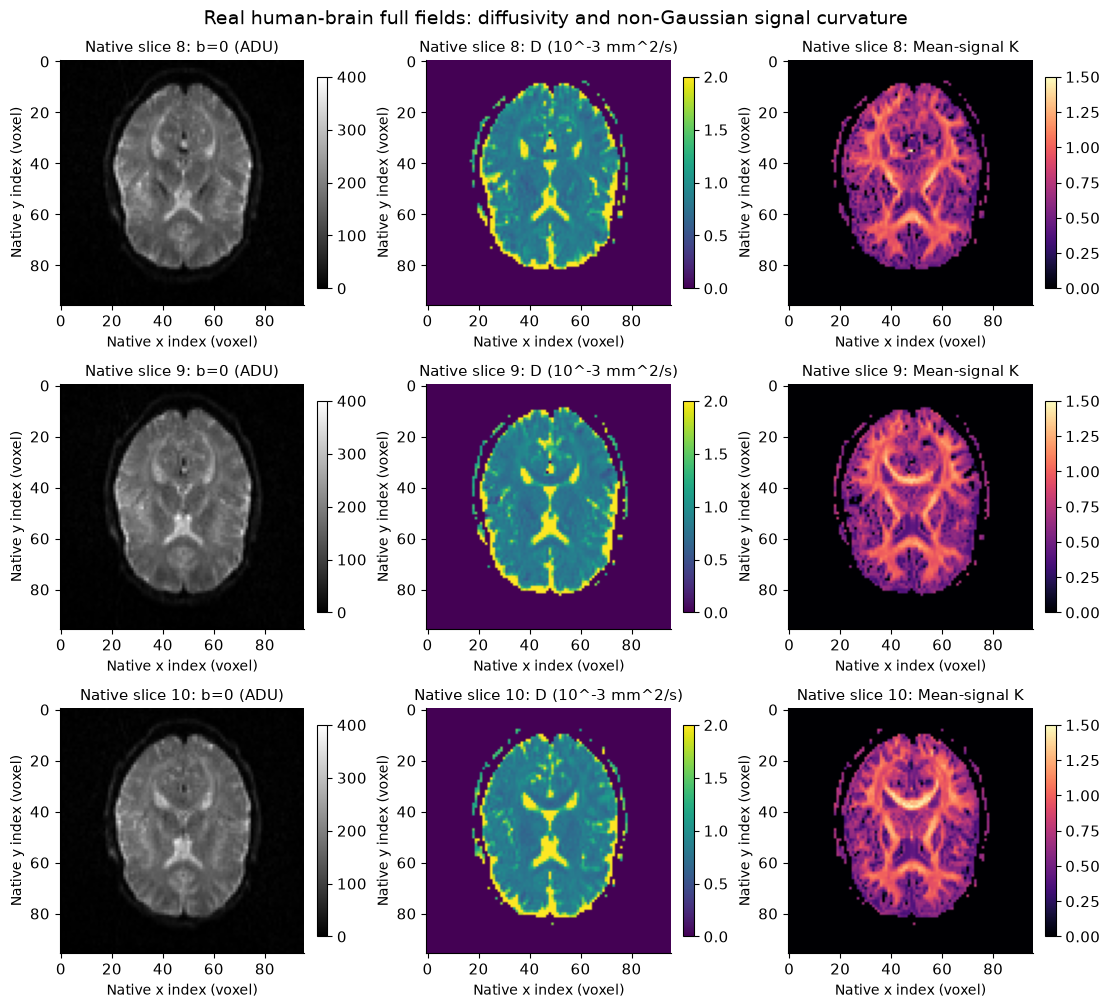

In [4]:
display(plots['01_native_slice_maps'])
plt.close(plots['01_native_slice_maps'])

### Weighting and model limits

The unweighted and reduced-shell estimates are freshly fit. The reduced shell choice follows a common clinical-like subset but is not relabeled as the full-data method. The negative-K map and original-versus-fresh error separate physical model limitations from numerical parity.


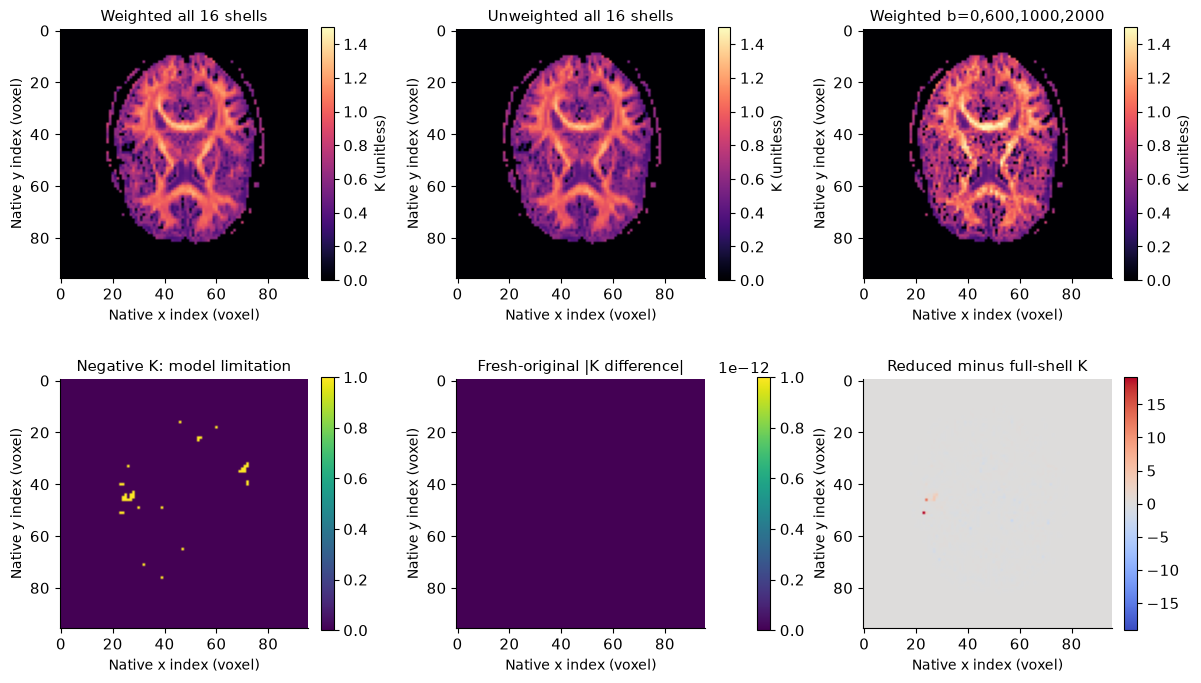

In [5]:
display(plots['02_weighting_and_model_limits'])
plt.close(plots['02_weighting_and_model_limits'])

### Signal model evidence

The three fixed coordinate ROIs compare actual direction-averaged observations with fresh kurtosis and Gaussian attenuation models. These curves assess forward consistency rather than hidden material accuracy. High-b departures and ROI heterogeneity remain visible.


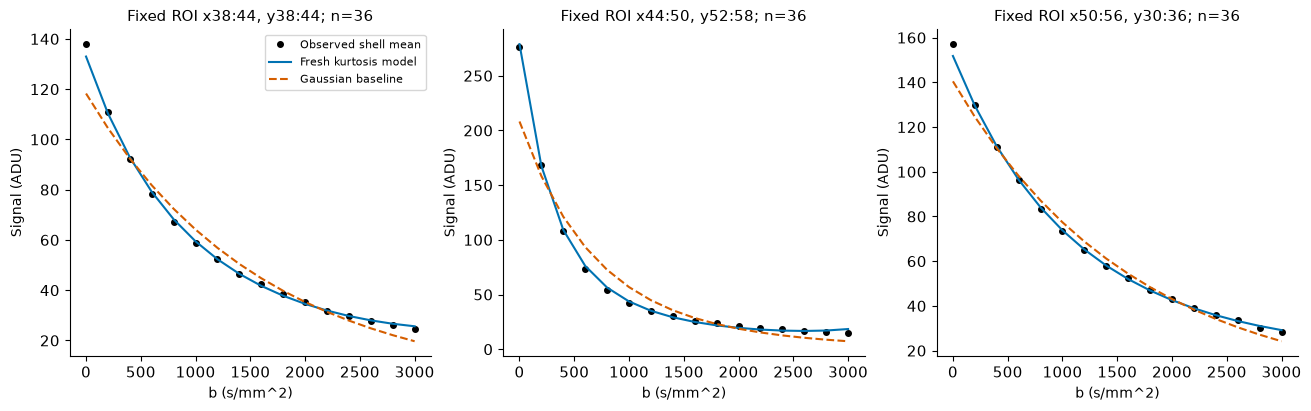

In [6]:
display(plots['03_signal_model_evidence'])
plt.close(plots['03_signal_model_evidence'])

### Cross slice and support

All slice summaries use the same observation-only support. Lower residual alone is not a proof of a uniquely correct tissue model. The support-count curve varies a public raw-signal threshold and does not select a favorable hidden answer.


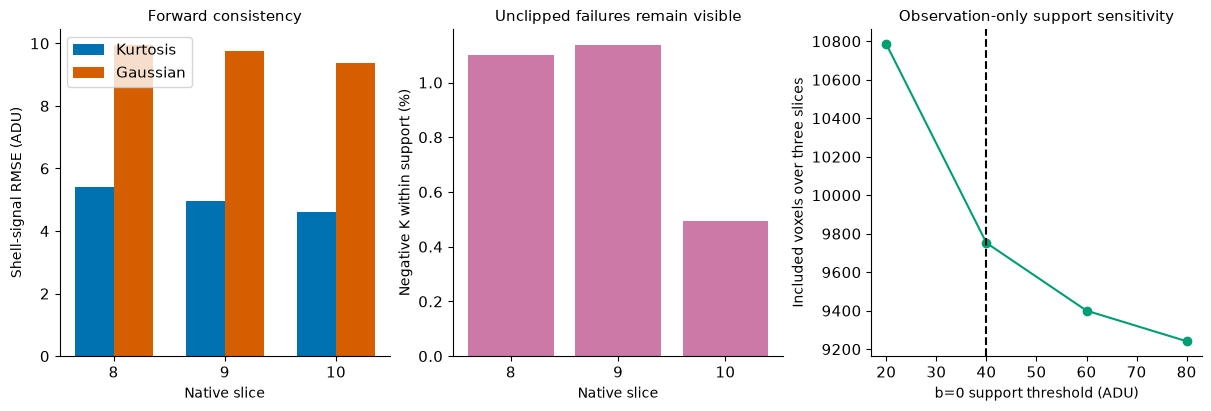

In [7]:
display(plots['04_cross_slice_and_support'])
plt.close(plots['04_cross_slice_and_support'])

In [8]:
measurement={'reconstruction_runtime_s':reconstruction_runtime,'experiment_runtime_s':experiment_runtime,
             'python':platform.python_version(),'numpy':np.__version__,'metrics':report['metrics']}
(root/'notebooks/reference_outputs/measurement.json').write_text(json.dumps(measurement,indent=2),encoding='utf8')
# An optional maintainer-owned export directory keeps publication figures out of the task runtime.
if os.environ.get('IMAGING_EXPORT_DIR'):
    values={**{k:v for k,v in fresh.items()},**{'experiment_'+k:v for k,v in experiments.items()}}
    export_figures(plots,Path(os.environ['IMAGING_EXPORT_DIR']),values)
print(json.dumps(measurement,indent=2))


{
  "reconstruction_runtime_s": 0.3065068998839706,
  "experiment_runtime_s": 0.6966464000288397,
  "python": "3.11.11",
  "numpy": "2.4.6",
  "metrics": {
    "diffusivity_relative_l2": 0.0,
    "reconstruction_relative_l2": 0.0,
    "baseline_relative_l2": 0.0,
    "forward_shell_rmse": 5.002890195639437
  }
}


## 6. Conclusion

### Conclusion and review record

Fresh original-method agreement validates the local mathematical extraction on these observations. The actual observation and calibration experiments above delimit the scientific interpretation; agreement with a standard reconstruction does not establish hidden physical truth. The notebook keeps physical failures and uncertain estimates visible.
